# Повтор проекта главы 13

Новая копия моего ранее выполненного проекта, текущие CSV из публичного пакета. Выборы и код переиспользованы явно; это повтор знакомых данных, а не новый слепой эксперимент. Все code-ячейки в этой копии будут реально исполнены заново в отдельном Python-процессе с чистым namespace.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
RANDOM_STATE=42
DATA=Path('data')
print('Python',sys.version.split()[0])
for lib in [pd,np,sklearn,matplotlib]: print(lib.__name__,lib.__version__)
pd.set_option('display.max_columns',30)
def new_model(class_weight=None):
    return make_pipeline(TfidfVectorizer(ngram_range=(1,2)),LogisticRegression(max_iter=1000,class_weight=class_weight))


Matplotlib is building the font cache; this may take a moment.
Python 3.12.14
pandas 3.0.6
numpy 2.4.6
sklearn 1.8.0
matplotlib 3.10.9


## 1. Цель

Найти кофейню с наибольшим ростом доли текстов с сигналом жалобы, затем по недельным данным выбрать границу. Управляющая получит таблицы, исходные ключи цитат и письмо. До оценки задаю ориентиры: модели должны обойти наиболее частый класс по accuracy, для тем дополнительно macro-F1; доли и их изменение описывают отзывы, а не посетителей.

## 2. Данные

In [2]:
r=pd.read_csv(DATA/'reviews_text.csv')
n=pd.read_csv(DATA/'reviews_new.csv',parse_dates=['date'])
print('Старые',r.shape,'новые',n.shape,'диапазон',n.date.min(),n.date.max())
print(n.groupby('shop_id').size())
print(r.isna().sum(),n.isna().sum())
print('Повторы ID',r.review_id.duplicated().sum(),n.review_id.duplicated().sum())
print('Повторяющиеся тексты старые/новые',r.text.duplicated().sum(),n.text.duplicated().sum())


Старые (2400, 5) новые (4800, 4) диапазон 2026-09-01 00:00:00 2026-10-31 00:00:00
shop_id
KZN-1    770
KZN-2    812
PRM-1    791
PRM-2    792
TMN-1    813
UFA-1    822
dtype: int64
review_id    0
shop_id      0
text         0
rating       0
topic        0
dtype: int64 review_id    0
date         0
shop_id      0
text         0
dtype: int64
Повторы ID 0 0
Повторяющиеся тексты старые/новые 249 773


**Вывод по данным.** Строки с повторяющимся текстом сохраняю: разные ID могут соответствовать разным отзывам. Дубли текста проверю отдельно при оценке обобщения. Новые отзывы не имеют рейтинга, поэтому модельная доля не равна измеренной доле жалоб.

## 3. Предобработка

Пропуски и уникальность ключей проверены выше. Нормализацию выполняет TF-IDF, отрицания сохраняются, добавлены биграммы. Новые прогнозы присоединяю по review_id, а не положением строк.

In [3]:
assert r.review_id.is_unique and n.review_id.is_unique
assert not r.isna().any().any() and not n.isna().any().any()
labels=sorted(r.topic.unique())
y=(r.rating<=3).astype(int)
quality=[]; text_quality_rows={k:{} for k in ['повторы','новые','без пересечения']}
models={}
for target,name in [(y,'sent'),(r.topic,'topic')]:
    a,b=train_test_split(r.index,test_size=.25,random_state=RANDOM_STATE,stratify=target)
    m=new_model().fit(r.loc[a,'text'],target.loc[a])
    pred=m.predict(r.loc[b,'text'])
    dummy=DummyClassifier(strategy='most_frequent').fit(r.loc[a,['text']],target.loc[a])
    quality.append(dict(target=name,n=len(b),acc=accuracy_score(target.loc[b],pred),dummy=accuracy_score(target.loc[b],dummy.predict(r.loc[b,['text']]))))
    repeated=r.loc[b,'text'].isin(r.loc[a,'text']).to_numpy()
    for key,mask in [('повторы',repeated),('новые',~repeated)]:
        text_quality_rows[key]['n_'+name]=int(mask.sum())
        text_quality_rows[key]['acc_'+name]=accuracy_score(target.loc[b].to_numpy()[mask],pred[mask])
        if name=='topic': text_quality_rows[key]['macro_f1_topic']=f1_score(target.loc[b].to_numpy()[mask],pred[mask],labels=labels,average='macro',zero_division=0)
    models[name]=new_model().fit(r.text,target)
    if name=='sent':
        acc_sent=round(quality[-1]['acc'],3)
        tn,fp,fn,tp=confusion_matrix(target.loc[b],pred,labels=[0,1]).ravel()
        tpr=tp/(tp+fn); fpr=fp/(fp+tn)
    else:
        acc_topic=round(quality[-1]['acc'],3)
        f1_by_topic=dict(zip(labels,f1_score(target.loc[b],pred,labels=labels,average=None,zero_division=0)))
        macro_f1=f1_score(target.loc[b],pred,labels=labels,average='macro',zero_division=0)
        rarest=target.loc[b].value_counts().idxmin()
        count_ratio=(pred==rarest).sum()/(target.loc[b]==rarest).sum()
        bal=new_model('balanced').fit(r.loc[a,'text'],target.loc[a])
        f1_rare_balanced=f1_score(target.loc[b],bal.predict(r.loc[b,'text']),labels=[rarest],average=None)[0]
a,b=next(GroupShuffleSplit(n_splits=1,test_size=.25,random_state=RANDOM_STATE).split(r,groups=r.text))
group_test_ids=r.iloc[b].review_id.tolist()
for target,name in [(y,'sent'),(r.topic,'topic')]:
    m=new_model().fit(r.iloc[a].text,target.iloc[a]);p=m.predict(r.iloc[b].text)
    text_quality_rows['без пересечения']['n_'+name]=len(b)
    text_quality_rows['без пересечения']['acc_'+name]=accuracy_score(target.iloc[b],p)
    if name=='topic':text_quality_rows['без пересечения']['macro_f1_topic']=f1_score(target.iloc[b],p,labels=labels,average='macro',zero_division=0)
text_quality=pd.DataFrame(text_quality_rows).T.round(3)
sent=models['sent']; topic_model=models['topic']
print(pd.DataFrame(quality).round(3).to_string(index=False))
print(text_quality.to_string())
print('F1 тем',f1_by_topic,'macro',macro_f1,'редчайшая',rarest,'ratio',count_ratio,'balanced F1',f1_rare_balanced)
print('Старый тест TPR/FPR',tpr,fpr)


target   n   acc  dummy
  sent 600 0.943  0.538
 topic 600 0.820  0.293
                 n_sent  acc_sent  n_topic  acc_topic  macro_f1_topic
повторы            82.0     0.939     81.0      1.000           1.000
новые             518.0     0.944    519.0      0.792           0.761
без пересечения   592.0     0.953    592.0      0.816           0.794
F1 тем {'атмосфера': np.float64(0.7346938775510204), 'доставка': np.float64(0.7918781725888325), 'еда': np.float64(0.7547169811320755), 'кофе': np.float64(0.8882978723404256), 'обслуживание': np.float64(0.844106463878327), 'цена': np.float64(0.7476635514018691)} macro 0.7935594864820916 редчайшая атмосфера ratio 0.6896551724137931 balanced F1 0.7586206896551724
Старый тест TPR/FPR 0.9169675090252708 0.034055727554179564


**Вывод по предобработке и оценке.** Модели проверены отдельно от финального обучения, ориентир most_frequent посчитан на тех же отложенных строках. Сравнение повторов, новых формулировок и группового разбиения выше ограничивает перенос случайного теста на новый источник. Macro-F1 учитывает каждую тему одинаково; balanced меняет компромисс, поэтому финальный заранее заданный конвейер оставлен без перевыбора по новым отзывам.

## 4. Анализ и модели

Месяцы period      до  после   рост
shop_id                     
KZN-2    0.371  0.564  0.193
PRM-2    0.356  0.438  0.082
TMN-1    0.560  0.609  0.049
PRM-1    0.402  0.444  0.042
KZN-1    0.360  0.387  0.027
UFA-1    0.408  0.383 -0.025 
Уровень TMN-1 рост KZN-2
Недельные доли shop_id     KZN-1  KZN-2  PRM-1  PRM-2  TMN-1  UFA-1
week                                                
2026-08-31  0.321  0.353  0.387  0.455  0.594  0.398
2026-09-07  0.407  0.396  0.477  0.351  0.600  0.511
2026-09-14  0.311  0.425  0.447  0.288  0.467  0.357
2026-09-21  0.375  0.330  0.337  0.337  0.575  0.407
2026-09-28  0.354  0.347  0.377  0.429  0.545  0.365
2026-10-05  0.364  0.596  0.480  0.519  0.675  0.348
2026-10-12  0.438  0.620  0.449  0.427  0.628  0.412
2026-10-19  0.405  0.555  0.443  0.444  0.667  0.356
2026-10-26  0.384  0.643  0.407  0.345  0.523  0.414
Недельные n shop_id     KZN-1  KZN-2  PRM-1  PRM-2  TMN-1  UFA-1
week                                                
2026-08-31     78  

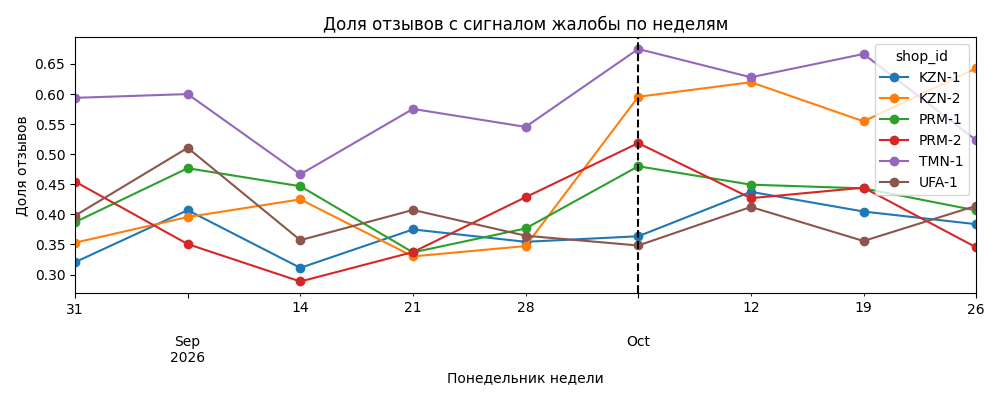

In [4]:
predictions=pd.DataFrame({'review_id':n.review_id,'p_neg':sent.predict_proba(n.text)[:,1],'topic':topic_model.predict(n.text)})
predictions=predictions.sample(frac=1,random_state=RANDOM_STATE)
n=n.merge(predictions,on='review_id',validate='one_to_one')
n['neg']=(n.p_neg>=.5).astype(int)
n['period']=np.where(n.date>=pd.Timestamp('2026-10-01'),'после','до')
by_shop=n.pivot_table(index='shop_id',columns='period',values='neg',aggfunc='mean')
by_shop['рост']=by_shop['после']-by_shop['до']
by_shop=by_shop.sort_values('рост',ascending=False)
worst_level=by_shop['после'].idxmax();worst_growth=by_shop['рост'].idxmax();focus_shop=worst_growth
n['week']=n.date.dt.to_period('W-SUN').dt.start_time
weekly=n.pivot_table(index='week',columns='shop_id',values='neg',aggfunc='mean')
weekly_counts=n.pivot_table(index='week',columns='shop_id',values='neg',aggfunc='size')
jump_week=weekly[focus_shop].diff().idxmax();change_date=jump_week
sept_max=round(weekly.loc[weekly.index<jump_week,focus_shop].max(),3)
print('Месяцы',by_shop.round(3).to_string(),'\nУровень',worst_level,'рост',worst_growth)
print('Недельные доли',weekly.round(3).to_string())
print('Недельные n',weekly_counts.to_string())
print('Выбор',focus_shop,change_date,'max до границы',sept_max)
ax=weekly.plot(figsize=(10,4),marker='o');ax.set(title='Доля отзывов с сигналом жалобы по неделям',xlabel='Понедельник недели',ylabel='Доля отзывов');ax.axvline(change_date,color='black',linestyle='--');plt.tight_layout();plt.savefig('own-weekly.png');plt.show()
n['period']=np.where(n.date>=change_date,'после','до')
focus=n[n.shop_id==focus_shop]
assert focus.groupby('period').size().min()>=30
bad=n[n.neg==1]
def theme_table(frame):
    return pd.crosstab(frame.topic,frame.period,normalize='columns')
kzn=theme_table(bad[bad.shop_id==focus_shop]);others=theme_table(bad[bad.shop_id!=focus_shop])
cause=(kzn['после']-kzn['до']).idxmax()
q=bad[(bad.shop_id==focus_shop)&(bad.period=='после')&(bad.topic==cause)].sort_values('p_neg',ascending=False).head(5)
quotes=q.text.tolist();quote_ids=q.review_id.tolist()
print('Темы среди сигналов выбранной точки',kzn.round(3).to_string())
print('Остальные точки',others.round(3).to_string())
print('Цитаты',q[['review_id','date','shop_id','text','p_neg','topic','week']].to_string(index=False))
print('Цепочка одного отзыва',n.set_index('review_id').loc[quote_ids[0]].to_dict())
n.to_csv('own-scored.csv',index=False);by_shop.to_csv('own-monthly.csv');weekly.to_csv('own-weekly.csv');q.to_csv('own-quotes.csv',index=False)


**Вывод по анализу.** Выбор точки сделан по максимальному приросту между календарными месяцами, граница — неделя максимального положительного шага этой точки. Темы ниже сравнивают только тексты с модельным сигналом; это другой знаменатель, чем все отзывы. Динамика и объёмы недель показаны, для операционного объяснения потребуется информация о работе смен и доставке.

In [5]:
observed=focus.groupby('period').neg.mean()
adj={key:round(float((p-fpr)/(tpr-fpr)),3) for key,p in observed.items()}
gold=pd.read_csv(DATA/'reviews_new_gold.csv')
g=n.merge(gold,on='review_id',validate='one_to_one',suffixes=('','_gold'))
assert g.label_source.eq('synthetic_kind_neg_or_mixed').all()
audit_rows=[]
for period,part in g[g.shop_id==focus_shop].groupby('period'):
    tn1,fp1,fn1,tp1=confusion_matrix(part.complaint,part.neg,labels=[0,1]).ravel()
    tp_rate=tp1/(tp1+fn1);fp_rate=fp1/(fp1+tn1);p=part.neg.mean()
    audit_rows.append(dict(period=period,n=len(part),complaints=int(part.complaint.sum()),tpr=tp_rate,fpr=fp_rate,observed=p,manual=part.complaint.mean(),adjusted=(p-fp_rate)/(tp_rate-fp_rate)))
audit=pd.DataFrame(audit_rows).set_index('period')
print('Доли всех отзывов выбранной точки',focus.groupby('period').neg.agg(['size','mean']).to_string())
print('Перенос старых TPR/FPR',adj)
print('Новые синтетические метки',audit.round(4).to_string())
print('3 октября при 1/5 октября:',pd.Timestamp('2026-10-03')>=pd.Timestamp('2026-10-01'),pd.Timestamp('2026-10-03')>=pd.Timestamp('2026-10-05'))
audit.to_csv('own-audit.csv')
letter=f"Управляющей сетью. Проверить {focus_shop} начиная с недели {change_date.date()}: доля отзывов с сигналом модели до/после выбранной даты {observed['до']:.1%}/{observed['после']:.1%}. Знаменатель — все отзывы этой точки в каждом периоде; граница включена в после. Наибольший прирост доли среди текстов с сигналом жалобы у темы {cause}. Это гипотеза для проверки операций, а не доказанная причина. Наибольший уровень октября у {worst_level}, максимальный прирост — {worst_growth}. Цитаты с исходными ID приведены ниже. Поправка по старым рейтинговым меткам даёт {adj}; её переносимость на жалобы не установлена. Синтетические контрольные метки не заменяют независимую человеческую разметку. Данные описывают отзывы, уникальных гостей и всех посетителей не считаем. Предлагаю проверить журнал доставки и смен, а также независимо разметить новые тексты обоих периодов."
letter+='\n\n'+'\n'.join(f'{i}: {t}' for i,t in zip(quote_ids,quotes))
Path('own-letter.md').write_text(letter)
print(letter)


Доли всех отзывов выбранной точки         size      mean
period                
до       440  0.368182
после    372  0.596774
Перенос старых TPR/FPR {'до': 0.378, 'после': 0.637}
Новые синтетические метки           n  complaints  tpr     fpr  observed  manual  adjusted
period                                                          
до      440         161  1.0  0.0036    0.3682  0.3659    0.3659
после   372         222  1.0  0.0000    0.5968  0.5968    0.5968
3 октября при 1/5 октября: True False
Управляющей сетью. Проверить KZN-2 начиная с недели 2026-10-05: доля отзывов с сигналом модели до/после выбранной даты 36.8%/59.7%. Знаменатель — все отзывы этой точки в каждом периоде; граница включена в после. Наибольший прирост доли среди текстов с сигналом жалобы у темы доставка. Это гипотеза для проверки операций, а не доказанная причина. Наибольший уровень октября у TMN-1, максимальный прирост — KZN-2. Цитаты с исходными ID приведены ниже. Поправка по старым рейтинговым меткам даёт {'до

**Вывод по поправке и письму.** Доля модельных сигналов KZN-2 при выбранной границе5октября36.8% до (440отзывов) и59.7% после (372отзыва). Условная поправка старым TPR/FPR даёт37.8%/63.7%; новые синтетические complaint36.59%/59.68%. Разница целей рейтинга и жалобы требует независимой проверки переноса. Письмо сохраняет исходныеID цитат и формулирует проверку доставки как гипотезу.

## 5. Выводы и рекомендации

Письмо выше содержит выбранную точку, дату, масштабы и исходные цитаты. Проверьте операционные журналы; по этим данным причинного эффекта не установлено. Оценка поправки на тех же синтетически размеченных строках алгебраически совпадает с долей меток и не проверяет будущую неделю. Для переноса нужны независимая человеческая разметка обоих периодов, доверительные интервалы, проверка TPR/FPR и устойчивости к выбору границы. Рост одной и той же линейной поправки не является доказательством переносимости.

### Проверенные результаты и чтение цитат

2400 старых/4800 новых отзывов, отсутствующих значений и дублей ID нет; повторов текстов249/773, они не удалены. Тест accuracy тональности0.943 против baseline0.538, тем0.820 против0.293; macro-F1тем0.794. У повторяющихся тестовых текстов F1тем1.000, у новых0.761; групповой контроль592отзыва даёт0.794. Это полезный контроль, но не независимая оценка живого источника.

По календарным месяцам KZN-2 имеет рост0.371→0.564 (+19.3п.п.), TMN-1 имеет максимальный уровень0.609. Граница KZN-2 —5октября: недельная доля0.347→0.596 при89отзывах в неделю скачка; следующие недели0.620,0.555,0.643. До/после выбранной даты440/372отзыва, модельный сигнал162/222, то есть36.8%/59.7%. Среди сигналов доставка24.1%→58.1%, у остальных точек18.1%→16.3%.

Все пять цитат упоминают адрес/курьера, пролитый кофе в пакете или неверный заказ. N-54090 также жалуется на капучино, N-53971 на приветствие, N-54719 на волос в салате; одна основная тема не исчерпывает содержание. Трасса N-54090:23октября,KZN-2,p=.9546,neg1,доставка,неделя19октября,письмо с тем же исходнымID.

Старые TPR=.917/FPR=.034 дают условные доли.378/.637. На синтетических complaint до161/440=.3659,после222/372=.5968; совпадение новой поправки на тех же строках не является проверкой будущего потока. 3октября относится к после при границе1октября и к до при границе5октября. Нужны независимо размеченные новые отзывы обоих периодов; о количестве уникальных гостей и доле посетителей данных нет.

## Дополнение к текущему брифу: письмо и знаменатели

In [6]:
counts=focus.groupby('period').neg.agg(signals='sum',n='size')
bad_counts=bad[bad.shop_id==focus_shop].groupby('period').size()
theme_counts=bad[(bad.shop_id==focus_shop)&(bad.topic==cause)].groupby('period').size()
summary=counts.join(bad_counts.rename('all_signals')).join(theme_counts.rename('delivery_signals'))
summary['signal_share']=summary.signals/summary.n
summary['topic_share_among_signals']=summary.delivery_signals/summary.all_signals
summary.to_csv('retest-period-summary.csv')
start=n.date.min().date();end=n.date.max().date();border=change_date.date()
lines=[f'Управляющей сетью. По синтетическому reviews_new.csv проверяем {focus_shop}.',
 f'До: {start} включительно до {border} исключительно; после: {border} включительно по {end} включительно. Единица — отзыв, не уникальный гость или посетитель.']
for period in ['до','после']:
 a=summary.loc[period]
 lines.append(f'{period}: сигналов {int(a.signals)}/{int(a.n)} всех отзывов точки = {a.signal_share:.1%}; основная тема {cause}: {int(a.delivery_signals)}/{int(a.all_signals)} всех сигналов этого периода = {a.topic_share_among_signals:.1%}.')
lines += [f'Точка выбрана по максимальному месячному приросту, неделя — {border}; максимум уровня октября у {worst_level}. В неделю скачка {int(weekly_counts.loc[change_date,focus_shop])} отзывов. Обе группы больше30; отдельные цитаты и редкие темы не трактуем как репрезентативную выборку.',
 'Прошу управляющую сопоставить с журналом доставок этой точки до/после: опоздания/все доставки, неверные заказы/все доставки, смены курьеров и упаковку. Это проверка гипотезы, причинный эффект по отзывам не установлен.',
 f'Поправка старыми рейтингами TPR={tpr:.3f}, FPR={fpr:.3f} даёт {adj}; перенос на жалобы и оба периода не доказан. reviews_new_gold.csv имеет label_source=synthetic_kind_neg_or_mixed: это генератор, не независимые люди.',
 'Следующий шаг: собрать новые реальные отзывы обоих периодов и независимо, вслепую разметить по единой инструкции (включая отмеченные и неотмеченные), оценить неопределённость долей и ошибок по периодам; затем решать об операционном вмешательстве.']
interpretations=['Подтверждает проблему поиска адреса; дополнительно негативно оценивает капучино.', 'Подтверждает проблему поиска адреса; дополнительно жалуется на отсутствие приветствия.', 'Подтверждает проблему поиска адреса и намерение не возвращаться.', 'Подтверждает пролитый кофе в упаковке; не доказывает опоздание.', 'Подтверждает неверный заказ; дополнительно содержит жалобу на волос в салате.']
for id,text,meaning in zip(quote_ids,quotes,interpretations):lines += [f'{id}: «{text}»',meaning]
lines += ['Цитаты подтверждают конкретные ситуации в этих текстах, не частоту среди всех гостей и не одну доказанную причину. Частоты тем посчитаны по всем сигналам соответствующего периода, одна основная тема не покрывает остальные упоминания.']
Path('letter-retest.md').write_text('\n\n'.join(lines))
print(summary.to_string());print('\n\n'.join(lines))


        signals    n  all_signals  delivery_signals  signal_share  topic_share_among_signals
period                                                                                      
до          162  440          162                39      0.368182                   0.240741
после       222  372          222               129      0.596774                   0.581081
Управляющей сетью. По синтетическому reviews_new.csv проверяем KZN-2.

До: 2026-09-01 включительно до 2026-10-05 исключительно; после: 2026-10-05 включительно по 2026-10-31 включительно. Единица — отзыв, не уникальный гость или посетитель.

до: сигналов 162/440 всех отзывов точки = 36.8%; основная тема доставка: 39/162 всех сигналов этого периода = 24.1%.

после: сигналов 222/372 всех отзывов точки = 59.7%; основная тема доставка: 129/222 всех сигналов этого периода = 58.1%.

Точка выбрана по максимальному месячному приросту, неделя — 2026-10-05; максимум уровня октября у TMN-1. В неделю скачка 89 отзывов. Обе группы бол

**Вывод.** Письмо выводит числители и знаменатели из тех же текущих строк, сохраняет обе границы периодов и исходные ID цитат. Содержимое цитат проверено отдельно от основной темы, внешний недостаток независимой человеческой разметки явно остаётся.

## Выводы и рекомендации

Точка KZN-2 с недели5октября требует проверки доставок:162/440 сигналов до и222/372 после,39/162 и129/222 из этих сигналов относятся к доставке. Письмо letter-retest.md содержит обе границы, исходные цитаты и описание дополнительных тем. Это повтор моего знакомого проекта на текущих CSV, не новый слепой эксперимент. Независимая человеческая разметка обоих периодов и операционный журнал остаются необходимыми для вывода о реальных жалобах и причине.